<p class="hz-kicker">Week 5 · Self-paced lab</p>

# Tuning a tree

Altamar's management liked the trees but asked a fair question: *how deep, and why should we trust it?* In this lab you turn the dials of a decision tree yourself, choose its depth with cross-validation, and turn its rules into decisions for the hotels.

<ul class="hz-lesson-meta"><li>≈ 2 hours</li><li>5 tasks</li><li>Runs in your browser</li><li>Graded quiz</li></ul>

**Recap of the [live session](https://hizocar.github.io/mba-business-analytics-1/sessions/Session_5_Live/):**

- A **decision tree** asks yes/no questions and answers with the **average of a group** of similar bookings (a rate, or a share that cancel).
- With no limit it **memorizes**: perfect on training bookings, much worse on new ones.
- **Cross-validation** compares settings on the training bookings only (5 folds, averaged) so the test set stays an honest final check.

Run this cell first. You don't need to read it: it loads the clean bookings, makes the usual train/test splits (25% test, `random_state=42`) and defines the helpers from the live session.

In [1]:
# Setup: libraries, the clean Altamar data, the train/test splits and a few helpers.
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score, KFold, StratifiedKFold
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeRegressor, DecisionTreeClassifier, plot_tree
from sklearn.metrics import r2_score, mean_absolute_error, roc_auc_score, accuracy_score
sns.set_theme(style="whitegrid")

DATA = "https://raw.githubusercontent.com/hizocar/mba-business-analytics-1/main/docs/datasets/"
df = pd.read_csv(DATA + "altamar_bookings_clean.csv")
df["arrival_month"] = pd.to_datetime(df["arrival_date"]).dt.month

CATS = ["hotel", "room_type", "customer_type", "channel", "deposit", "country"]
NUMS = ["lead_time_days", "nights", "weekend_nights", "adults", "children", "repeat_guest",
        "previous_cancellations", "special_requests", "parking", "arrival_month"]

def rate_X(rows, month_as="number", drop_first=False):
    """Inputs for the rate question. The linear model gets one column per month (session 3);
    a tree can use the month as a number and group the months itself."""
    X = rows[NUMS + CATS].copy()
    cats = CATS + (["arrival_month"] if month_as == "dummies" else [])
    if month_as == "dummies":
        X["arrival_month"] = X["arrival_month"].astype(str)
    X = pd.get_dummies(X, columns=cats, drop_first=drop_first, dtype=float)
    return X if drop_first else X.reindex(columns=RATE_COLS[month_as], fill_value=0.0)

RATE_COLS = {m: list(rate_X(df, m, drop_first=True).columns) for m in ["number", "dummies"]}
Xr, Xr_lin, y_rate = rate_X(df, "number"), rate_X(df, "dummies"), df["adr"]
Xr_train, Xr_test, yr_train, yr_test = train_test_split(Xr, y_rate, test_size=0.25, random_state=42)
Xl_train, Xl_test = train_test_split(Xr_lin, test_size=0.25, random_state=42)  # the same bookings

Xc = pd.get_dummies(df[NUMS + CATS + ["adr"]], columns=CATS, drop_first=True, dtype=float)
y_cancel = df["canceled"]
Xc_train, Xc_test, yc_train, yc_test = train_test_split(Xc, y_cancel, test_size=0.25, random_state=42, stratify=y_cancel)

def rate_scores(name, model, X_train, X_test):
    """One row of a comparison table for the rate question."""
    return {"model": name, "R² train": r2_score(yr_train, model.predict(X_train)),
            "R² test": r2_score(yr_test, model.predict(X_test)),
            "typical error, test (USD)": mean_absolute_error(yr_test, model.predict(X_test))}

def cancel_scores(name, model, X_train, X_test):
    """One row of a comparison table for the cancellation question."""
    return {"model": name, "accuracy train": accuracy_score(yc_train, model.predict(X_train)),
            "accuracy test": accuracy_score(yc_test, model.predict(X_test)),
            "AUC test": roc_auc_score(yc_test, model.predict_proba(X_test)[:, 1])}

def table(rows):
    """Print a list of score rows as a small, rounded table."""
    print(pd.DataFrame(rows).set_index("model").round(3).to_string(), "\n")

def tree_rules(model, columns):
    """Every leaf of a fitted tree as a readable rule, with its size and its answer."""
    t, rows = model.tree_, []
    def walk(node, conds):
        if t.children_left[node] == -1:
            v = t.value[node][0]
            answer = v[1] / v.sum() if len(v) > 1 else v[0]
            rows.append({"rule": " and ".join(describe(conds)) or "all bookings",
                         "bookings": int(t.n_node_samples[node]), "answer": answer})
            return
        f, thr = columns[t.feature[node]], t.threshold[node]
        walk(t.children_left[node], conds + [(f, "<=", thr)])
        walk(t.children_right[node], conds + [(f, ">", thr)])
    walk(0, [])
    return pd.DataFrame(rows)

LEAD_BINS = [0, 15, 30, 45, 60, 90, 120, 150, 200, 400]
LEAD_LABELS = ["0–15", "16–30", "31–45", "46–60", "61–90", "91–120", "121–150", "151–200", "201+"]
MONTHS = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

def describe(conds):
    """Merge the conditions on a path into short, plain phrases."""
    lo, hi, out, is_, not_ = {}, {}, [], {}, {}
    for f, op, thr in conds:
        cat = next((c for c in CATS if f.startswith(c + "_")), None)
        if cat:
            (not_ if op == "<=" else is_).setdefault(cat, []).append(f[len(cat) + 1:])
        elif op == "<=":
            hi[f] = min(hi.get(f, np.inf), thr)
        else:
            lo[f] = max(lo.get(f, -np.inf), thr)
    for cat in dict.fromkeys(c for c in CATS if c in is_ or c in not_):
        name = cat.replace("_", " ")
        out.append(f"{name} is {is_[cat][0]}" if cat in is_ else f"{name} is not {not_[cat][0]}" if len(not_[cat]) == 1 else f"{name} is neither {' nor '.join(not_[cat])}")
    for f in dict.fromkeys(f for f, _, _ in conds if f in lo or f in hi):
        if f == "adr":
            a, b = lo.get(f), hi.get(f)
            out.append(f"rate USD {a:.0f}–{b:.0f}" if a and b else f"rate > USD {a:.0f}" if a else f"rate ≤ USD {b:.0f}")
            continue
        a = int(np.floor(lo[f])) + 1 if f in lo else None
        b = int(np.floor(hi[f])) if f in hi else None
        if f == "arrival_month":
            a, b = a or 1, b or 12
            out.append(f"arrives in {MONTHS[a - 1]}" + (f"–{MONTHS[b - 1]}" if b > a else ""))
            continue
        name = f.replace("_", " ").replace(" days", "")
        out.append(f"{name} {a}–{b}" if a is not None and b is not None else f"{name} ≥ {a}" if a is not None else f"{name} = 0" if b == 0 else f"{name} ≤ {b}")
    return out

print(f"{len(df):,} bookings. Rate question: {len(Xr_train):,} train / {len(Xr_test):,} test. "
      f"Cancellation question: {len(Xc_train):,} train / {len(Xc_test):,} test ({y_cancel.mean():.1%} cancel).")

experiments = []  # Task 1 keeps a log of your runs here

5,964 bookings. Rate question: 4,473 train / 1,491 test. Cancellation question: 4,473 train / 1,491 test (33.7% cancel).


## <span class="hz-step-n">01</span> How deep? Train versus test error

`max_depth` is the most important dial of a tree: how many questions a booking answers at most. This cell fits a rate tree with your depth and adds the result to a chart of **all your runs so far**.

**What to do:** run it with `MAX_DEPTH = 3`, then change it to 6, 10, 15 and 25, running the cell after each change. Watch the two lines grow.

Depth 3, 8 groups: typical error USD 23.1 on training bookings, USD 22.7 on test bookings.


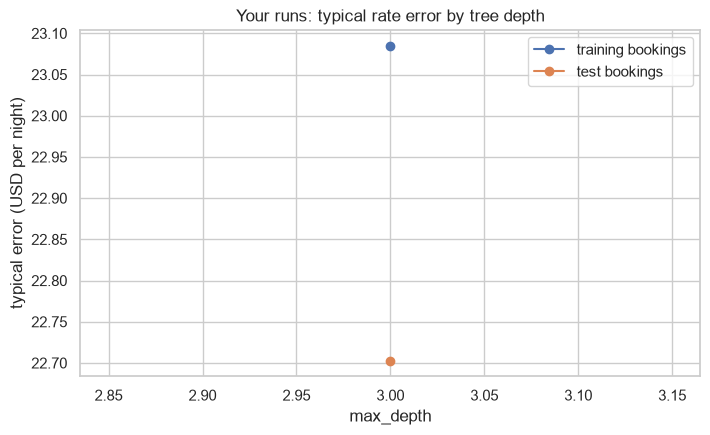

In [2]:
# ✏️ Change these settings
MAX_DEPTH = 3
tree = DecisionTreeRegressor(max_depth=MAX_DEPTH, random_state=42).fit(Xr_train, yr_train)
train_err = mean_absolute_error(yr_train, tree.predict(Xr_train))
test_err = mean_absolute_error(yr_test, tree.predict(Xr_test))
experiments.append({"depth": tree.get_depth(), "train": train_err, "test": test_err})
print(f"Depth {tree.get_depth()}, {tree.get_n_leaves():,} groups: typical error USD {train_err:.1f} on training bookings, USD {test_err:.1f} on test bookings.")
log = pd.DataFrame(experiments).drop_duplicates("depth", keep="last").sort_values("depth")
plt.figure(figsize=(8, 4.5))
plt.plot(log["depth"], log["train"], "o-", label="training bookings")
plt.plot(log["depth"], log["test"], "o-", label="test bookings")
plt.title("Your runs: typical rate error by tree depth")
plt.xlabel("max_depth"); plt.ylabel("typical error (USD per night)"); plt.legend()
plt.show()

**Think about it:** what happens to the training error as you raise `MAX_DEPTH`? And to the test error? Where would you stop, and why?

<details><summary>Show the answer</summary>

The **training error always falls**, to USD 0 at depth 25: every booking gets its own group. The **test error falls until about depth 10–12** (about USD 13 a night), then creeps back up (about USD 14 at depth 15+). The growing gap is memorization. Stop where the test error stops improving: deeper buys nothing on new bookings. (Task 3 makes this choice without peeking at the test set.)

</details>

The same idea on one hotel and one input. Turn the dial and compare the two errors with what you just saw.

<div class="hz-widget" data-widget="complexity-dial">
<p>▶ Interactive simulator: <a href="https://hizocar.github.io/mba-business-analytics-1/sessions/Session_5_Lab/">open this session on the course website</a> to use it.</p>
</div>

## <span class="hz-step-n">02</span> The smallest group a tree may answer from

A second dial, `min_samples_leaf`, sets the **smallest group** the tree may use for an answer. In business terms: *never quote a rate based on fewer than N bookings.* This cell grows a tree with **no depth limit** but with your minimum group size.

**What to do:** run it with `MIN_SAMPLES_LEAF = 1`, then try 5, 10, 50 and 200.

In [3]:
# ✏️ Change these settings
MIN_SAMPLES_LEAF = 1
tree = DecisionTreeRegressor(min_samples_leaf=MIN_SAMPLES_LEAF, random_state=42).fit(Xr_train, yr_train)
table([rate_scores(f"no depth limit, min_samples_leaf={MIN_SAMPLES_LEAF}", tree, Xr_train, Xr_test)])
print(f"{tree.get_n_leaves():,} groups, up to {tree.get_depth()} questions deep.")
print(f"Every predicted rate is the average of at least {MIN_SAMPLES_LEAF} training booking(s).")

                                    R² train  R² test  typical error, test (USD)
model                                                                           
no depth limit, min_samples_leaf=1       1.0    0.878                     14.263 

4,465 groups, up to 26 questions deep.
Every predicted rate is the average of at least 1 training booking(s).


**Think about it:** how do the number of groups and the gap between R² train and R² test change as you raise `MIN_SAMPLES_LEAF`? Which value would you defend in front of the revenue manager?

<details><summary>Show the answer</summary>

With 1: about 4,465 groups for 4,473 bookings, R² train 1.00, test 0.88. With **5 to 10**: a few hundred groups and test R² *rises* to 0.90–0.91 (typical error about USD 12), because the tree can no longer chase single bookings. With 50 the gap almost closes but real patterns get missed (test 0.86); 200 is far too coarse (0.49). Around 10 is easy to defend: every quoted rate rests on at least ten real bookings, and it scores best on new ones.

</details>

## <span class="hz-step-n">03</span> Choose the depth with cross-validation

In task 1 you looked at the test set to choose, which spends the honest final check. Now choose the depth of the **cancellation** tree the right way: 5-fold cross-validation on the training bookings only, scored with AUC. With 11 depths and 5 folds this is 55 fits; it takes a few seconds.

<div class="hz-widget" data-widget="kfold">
<p>▶ Interactive simulator: <a href="https://hizocar.github.io/mba-business-analytics-1/sessions/Session_5_Lab/">open this session on the course website</a> to use it.</p>
</div>

This cell computes the average validation AUC (and its spread across the folds) for each depth and plots the curve.

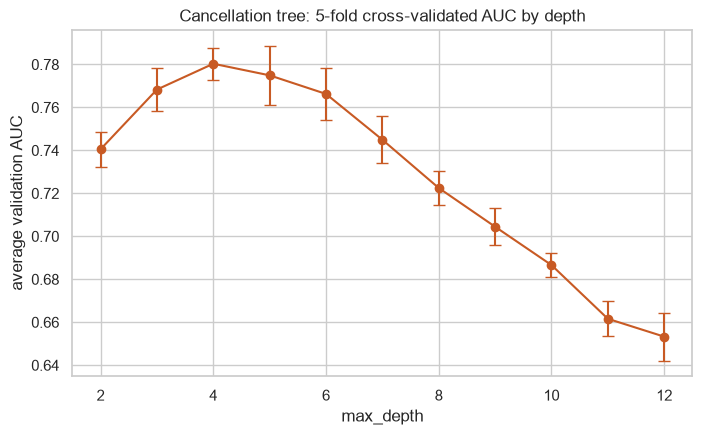

 depth  mean AUC  spread (std)
     2     0.741         0.008
     3     0.768         0.010
     4     0.780         0.007
     5     0.775         0.014
     6     0.766         0.012
     7     0.745         0.011
     8     0.722         0.008
     9     0.704         0.009
    10     0.687         0.006
    11     0.662         0.008
    12     0.653         0.011


In [4]:
# ✏️ Change these settings
DEPTHS = range(2, 13)
FOLDS = 5
cv = StratifiedKFold(n_splits=FOLDS, shuffle=True, random_state=42)
rows = []
for d in DEPTHS:
    s = cross_val_score(DecisionTreeClassifier(max_depth=d, random_state=42), Xc_train, yc_train, cv=cv, scoring="roc_auc")
    rows.append({"depth": d, "mean AUC": s.mean(), "spread (std)": s.std()})
curve = pd.DataFrame(rows)
plt.figure(figsize=(8, 4.5))
plt.errorbar(curve["depth"], curve["mean AUC"], yerr=curve["spread (std)"], marker="o", capsize=4, color="#c85a24")
plt.title(f"Cancellation tree: {FOLDS}-fold cross-validated AUC by depth")
plt.xlabel("max_depth"); plt.ylabel("average validation AUC")
plt.show()
print(curve.round(3).to_string(index=False))

**Think about it:** which depth would you choose? Is the best average the only thing that matters? Look at the spread too.

<details><summary>Show the answer</summary>

The curve is an upside-down U: AUC rises from about 0.74 at depth 2 to its peak, **about 0.78 at depth 4**, then falls steadily (about 0.65 at depth 12). Depth 5 (0.775) is within the spread of depth 4, so the two are practically tied; when two settings tie, prefer the **simpler** one, which here is also the best: **depth 4**. A justification a manager accepts: "on bookings it had not seen, depth 4 ranked risky bookings best, and deeper trees got steadily worse because they memorize noise."

</details>

## <span class="hz-step-n">04</span> From rules to operational actions

This cell fits the cancellation tree with your chosen depth, checks it **once** on the test set, and prints its riskiest and safest groups. Groups smaller than `MIN_BOOKINGS` are left out: too few bookings to build a policy on.

In [5]:
# ✏️ Change these settings
CHOSEN_DEPTH = 4
MIN_BOOKINGS = 50
tree = DecisionTreeClassifier(max_depth=CHOSEN_DEPTH, random_state=42).fit(Xc_train, yc_train)
print(f"Test AUC with depth {CHOSEN_DEPTH}: {roc_auc_score(yc_test, tree.predict_proba(Xc_test)[:, 1]):.3f}\n")
rules = tree_rules(tree, list(Xc_train.columns))
rules = rules[rules["bookings"] >= MIN_BOOKINGS].sort_values("answer", ascending=False)
for title, part in [("Riskiest groups", rules.head(3)), ("Safest groups", rules.tail(3))]:
    print(title)
    for _, r in part.iterrows():
        print(f"  {r['answer']:>4.0%} cancel  ({r['bookings']:>4} bookings)  if {r['rule']}")

Test AUC with depth 4: 0.752

Riskiest groups
   81% cancel  ( 607 bookings)  if channel is Online travel agency and deposit is not Non-refundable and lead time 46–132
   68% cancel  (  62 bookings)  if lead time ≤ 45 and previous cancellations ≥ 1 and weekend nights ≥ 2 and rate > USD 124
   55% cancel  ( 521 bookings)  if channel is not Online travel agency and deposit is not Non-refundable and lead time ≥ 61
Safest groups
   13% cancel  (1437 bookings)  if deposit is not Non-refundable and lead time ≤ 45 and previous cancellations = 0 and rate ≤ USD 138
   10% cancel  ( 108 bookings)  if deposit is Non-refundable and lead time ≤ 45 and previous cancellations = 0 and rate > USD 138
    5% cancel  ( 220 bookings)  if deposit is Non-refundable and lead time ≤ 45 and previous cancellations = 0 and rate ≤ USD 138


**Think about it:** pick two of these rules and turn each one into an **operational action** for Altamar: who does what, for which bookings, and what you expect to change.

<details><summary>Show the answer</summary>

Two examples (yours may differ):

1. **About 81% of agency bookings made 46–132 days ahead without a deposit cancel.** Oversell more rooms on dates full of them, and ask these guests to reconfirm 30 days before arrival, releasing unconfirmed rooms early.
2. **Short-lead bookings with a non-refundable deposit and no previous cancellations almost never cancel (5–10%).** Treat them as firm: never count them as rooms to oversell. A small discount for paying a deposit moves more guests into this group.

A good action names the segment, the decision and the number that should move.

</details>

## <span class="hz-step-n">05</span> Does the model know each hotel's season?

This cell predicts the rate of the same **typical booking** (a leisure guest, 2 adults, 3 nights, booked 30 days ahead through an agency) for every hotel and every arrival month, once with the linear model of week 3 and once with a tree. Solid lines are the tree, dashed lines the linear model.

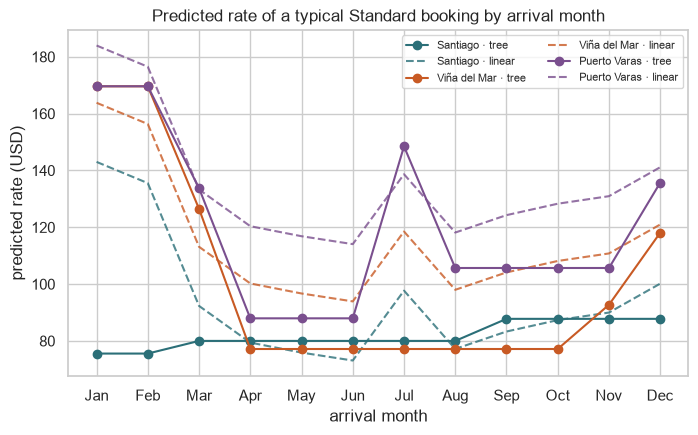

In [6]:
# ✏️ Change these settings
RATE_DEPTH = 10
ROOM = "Standard"
lin = LinearRegression().fit(Xl_train, yr_train)
tree = DecisionTreeRegressor(max_depth=RATE_DEPTH, random_state=42).fit(Xr_train, yr_train)
grid = pd.DataFrame([{"hotel": h, "arrival_month": m} for h in ["Santiago", "Viña del Mar", "Puerto Varas"] for m in range(1, 13)])
grid = grid.assign(lead_time_days=30, nights=3, weekend_nights=1, adults=2, children=0, repeat_guest=0, previous_cancellations=0, special_requests=1,
                   parking=0, room_type=ROOM, customer_type="Leisure", channel="Online travel agency", deposit="No deposit", country="Chile")
grid["linear"], grid["tree"] = lin.predict(rate_X(grid, "dummies")), tree.predict(rate_X(grid, "number"))
fig, ax = plt.subplots(figsize=(8, 4.5))
for (hotel, g), color in zip(grid.groupby("hotel", sort=False), ["#2b6f78", "#c85a24", "#7a4f8e"]):
    ax.plot(g["arrival_month"], g["tree"], "o-", color=color, label=f"{hotel} · tree")
    ax.plot(g["arrival_month"], g["linear"], "--", color=color, alpha=0.8, label=f"{hotel} · linear")
ax.set_xticks(range(1, 13), MONTHS); ax.legend(ncol=2, fontsize=8)
ax.set_title(f"Predicted rate of a typical {ROOM} booking by arrival month"); ax.set_xlabel("arrival month"); ax.set_ylabel("predicted rate (USD)")
plt.show()

**Think about it:** compare the three dashed lines with each other, then the three solid lines. What can the tree say that the linear model cannot? Try `ROOM = "Suite"`.

<details><summary>Show the answer</summary>

The **dashed lines are parallel**: the linear model gives every hotel the same January bonus and the same July bonus, and only shifts each line up or down. So it predicts a summer peak for Santiago too, which is wrong. The **solid lines each have their own shape**: Santiago dips in January–February and rises from September; Viña del Mar peaks in summer; Puerto Varas in summer *and* July. The tree found these **interactions** (hotel × month) by itself. Its lines are also step-shaped: neighbouring months in the same group share one rate.

</details>

## Graded quiz

Five questions on this week's ideas. They count for **5% of the module grade**, and **only your first submission counts**, so finish the lab before you start. Use the name and email you are registered with in the program.

<div class="hz-widget" data-widget="graded-quiz">
<script type="application/json">{"id": "session-5", "title": "Week 5 quiz", "questions": [{"q": "A rate tree has a typical error of USD 2 on its training bookings and USD 18 on its test bookings. A tree with half the depth has USD 11 and USD 13. What is going on?", "options": ["The deeper tree is better, because its training error is lower", "The deeper tree is memorizing its training bookings; the shallower one generalizes better", "The test set must contain errors, because the training error is so low", "Both trees are equivalent, because their average error is similar"]}, {"q": "Why does Altamar's team use 5-fold cross-validation to choose the depth instead of the test set?", "options": ["Because cross-validation makes the model run faster in production", "So the test set stays untouched for one honest final check, and the choice rests on five scores instead of one", "Because cross-validation trains a better tree than the test set", "Because the test set is too small to compute an AUC"]}, {"q": "Cross-validated AUC for the cancellation tree: depth 2 → 0.74, depth 4 → 0.78, depth 6 → 0.77, depth 8 → 0.72, depth 12 → 0.65 (spread about ±0.01). Which depth do you choose?", "options": ["Depth 8, the middle of the range", "Depth 2, because the simplest tree is always best", "Depth 12, because the deepest tree learns the most rules", "Depth 4: the highest validation AUC, and simpler than the near-tie at depth 6"]}, {"q": "The revenue manager sets min_samples_leaf = 10 on the rate tree. What does that mean for the rates it quotes?", "options": ["Each quoted rate is the average of at least 10 training bookings, so the tree cannot chase single bookings", "Only the 10 most important inputs are used", "Each rate is rounded to the nearest USD 10", "The tree can ask at most 10 questions"]}, {"q": "The depth-4 tree finds that about 80% of online-agency bookings made 46–132 days ahead without a non-refundable deposit cancel. Which action follows best from this rule?", "options": ["For arrival dates with many of these bookings, oversell more rooms and ask these guests to reconfirm about 30 days before arrival", "Retrain the tree with no depth limit to find a more precise percentage", "Raise the rate of every booking by 80%", "Stop accepting online-agency bookings altogether"]}]}</script>
</div>